# Provincia de Santiago — Clasificación de morfología Liu (SGBNet)

Clasifica **toda la Provincia de Santiago** (límite administrativo de OSM, relación
1674530, ~2.000 km²) con las 6 clases de morfología de red vial de Liu et al. (2025):
Regular Grid, Irregular Grid, Broken Grid, Warped Parallel, Loops & Lollipops y Sparse.

- Grilla de parches de **1×1 km Web Mercator** sobre el polígono provincial (~2.900 parches).
- Para cada parche se construye el grafo street-block (réplica exacta del pipeline USNMS,
  verificada contra el h5 original) y se clasifica con **SGBNet reentrenado en la RTX 5060**
  (accuracy 0.775 en test).
- Integra las **mediciones acústicas reales** de `Puntos_medicion_data_sant26.csv`.

Requisito: ejecutar antes `descarga_red_santiago.py` (una sola vez), que deja la red
drive completa en `datos/red_drive_santiago.parquet`.

**Entorno: `geo03-cpu` o `geo03-gpu`**; para los 1.286 parches se recomienda GPU.

**ARCHIVO_MEDICIONES** Debe contener los siguientes valores:
`ID` (T04, L01)
`CALLE` (Nombre vía)
`CAT_OGUC` (Troncal, Colectora)
`FECHA` (23/01/2026)
`PERIORO` (Día, Tarde, Noche)
`LATITUD` (WGS84 en decimales -33.458527)
`LONGITUD` (WGS84 en decimales -70.7343939)
`LA_EQ`   (Nivel equivalente 68.2)
`LA_MIN` (Nivel mínimo 48.6)
`LA_MAX`  (Nivel máximo 74.7)

In [9]:
# ============================================================
# CONFIGURACIÓN GENERAL DEL ESTUDIO
# ============================================================

NOMBRE_CIUDAD = "santiago"           # Se usará en títulos de mapas, reportes y logs, en minusculas
TAM_PARCHE_M = 300.0                # Tamaño del parche en metros (1000 m estándar Liu, o 300 m)
ARCHIVO_MEDICIONES = "Puntos_medicion_data_sant26.csv"   # Mediciones acústicas en sitio


# Archivos de entrada (dentro de datos/)
ARCHIVO_LIMITE = f"limite_{NOMBRE_CIUDAD.lower()}.geojson"      # Polígono que delimita el área (provincia, comuna o ciudad)
ARCHIVO_RED_VIAL = f"red_drive_{NOMBRE_CIUDAD.lower()}.parquet"         # Red vial descargada de OSM
# ARCHIVO_MEDICIONES = "Puntos_valdivia_13agos26.csv"   # Mediciones acústicas en sitio
# ARCHIVO_SUBDIVISIONES = "subdivisiones.geojson"# Comunas, distritos o barrios (opcional) no implementado

# Archivos de salida (dentro de datos/)
ARCHIVO_PARCHES_OUT = f"parches_liu_{NOMBRE_CIUDAD.lower()}.geojson"
ARCHIVO_MAPA_OUT = f"mapa_{NOMBRE_CIUDAD.lower()}_morfologia.png"

In [10]:
# ============================================================
# 1. Librerías, modelo y datos base
# ============================================================

import json
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import shapely
from shapely.geometry import Point, box
from shapely.ops import unary_union, polygonize

import torch
from torch_geometric.data import Data, Batch

# Repositorio aumilab-experimentos (código del paper de Liu y mediciones reales).
# Estructura esperada: ambos repos clonados lado a lado:
#   <workspace>/osm/scan_geo04_santiago_liu   <- este notebook
#   <workspace>/aumilab-experimentos          <- repo hermano
# Si está en otra ubicación, definir la variable de entorno AUMILAB_REPO.

# '''
# AUMILAB = Path(os.environ.get("AUMILAB_REPO", "../aumilab-experimentos")).resolve()
# FUSION_CODE = (AUMILAB / "liu_paper" /
#                "Urban-Street-Network-Morphology-Classification-Through-SGBNet-and-Fusion-Models" /
#                "fusionmodelcode")
# if not FUSION_CODE.exists():
#     raise FileNotFoundError(
#         f"No se encontró el código del paper de Liu en: {FUSION_CODE}\n"
#         "Clona el repositorio aumilab-experimentos junto al repo osm "
#         "(carpetas hermanas) o define la variable de entorno AUMILAB_REPO."
#     )
# LIU_DIR = Path("../scan_geo03_osm_real/liu_clasificacion")
# DATOS = Path("datos")

# sys.path.insert(0, str(FUSION_CODE))
# from config import possible_models
# from models import DynamicModel

# '''

MODELO_DIR = Path("01_clas/00_in")
DATOS = Path("00_descarga")
DATOS_OUT = Path("01_clas")

# De la carpeta Aumilab a una ubicación "local" liu_clasificación
sys.path.insert(0, str(MODELO_DIR.resolve()))
from config import possible_models
from models import DynamicModel


DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

with open(MODELO_DIR / "clases_liu.json", encoding="utf-8") as f:
    meta_liu = json.load(f)
CLASES = {int(k): v for k, v in meta_liu["clases"].items()}

with open(MODELO_DIR / "scalers_gnn0.json", encoding="utf-8") as f:
    sc = json.load(f)
MM_MIN = np.array(sc["minmax_data_min"]); MM_MAX = np.array(sc["minmax_data_max"])
STD_MEAN = np.array(sc["standard_mean"]); STD_SCALE = np.array(sc["standard_scale"])

config = {"gnn0": possible_models["gnn0"], "label": possible_models["label"]}
model = DynamicModel(config, num_classes=6).to(DEVICE)
model.load_state_dict(torch.load(MODELO_DIR / "best_model_retrained.pth", map_location=DEVICE))
model.eval()

prov = gpd.read_file(DATOS / ARCHIVO_LIMITE).to_crs(3857)
poligono_prov = prov.geometry.iloc[0]

edges = gpd.read_parquet(DATOS / ARCHIVO_RED_VIAL)
print("Aristas dirigidas:", len(edges), "| Provincia:", round(poligono_prov.area / 1e6), "km² Mercator")


Device: cuda:0 NVIDIA GeForce RTX 5060 Ti
Aristas dirigidas: 238238 | Provincia: 2917 km² Mercator


In [11]:
# ============================================================
# 2. Grilla de parches 1×1 km sobre la provincia
# ============================================================

TAM = TAM_PARCHE_M
minx, miny, maxx, maxy = poligono_prov.bounds
x0 = math.floor(minx / TAM) * TAM
y0 = math.floor(miny / TAM) * TAM

celdas = []
fila = 0
y = y0
while y < maxy:
    col = 0
    x = x0
    while x < maxx:
        celda = box(x, y, x + TAM, y + TAM)
        if celda.intersects(poligono_prov):
            celdas.append({"fila": fila, "col": col, "geometry": celda})
        x += TAM
        col += 1
    y += TAM
    fila += 1

print("Parches que intersectan la provincia:", len(celdas))


Parches que intersectan la provincia: 33042


In [12]:
# ============================================================
# 3. Construcción del grafo street-block (réplica USNMS verificada)
# ============================================================

FEATURE_KEYS = ["area", "circuity", "concavity", "number_of_linestrings",
                "formfacter", "rectanglarity", "elongation", "degree"]

def features_bloque(blk):
    A = blk.area; P = blk.length
    ch = blk.convex_hull
    mrr = shapely.minimum_rotated_rectangle(blk)
    if mrr.geom_type != "Polygon":       # bloques degenerados
        return None
    xs, ys = mrr.exterior.coords.xy
    pts = np.column_stack([xs, ys])[:4]
    l1 = np.linalg.norm(pts[1] - pts[0]); l2 = np.linalg.norm(pts[2] - pts[1])
    largo, ancho = max(l1, l2), min(l1, l2)
    c = blk.centroid
    rmax = max(c.distance(Point(p)) for p in blk.exterior.coords)
    return {
        "area": A,
        "circuity": 4 * math.pi * A / P**2 if P > 0 else 0.0,
        "concavity": A / ch.area if ch.area > 0 else 0.0,
        "formfacter": A / (math.pi * rmax**2) if rmax > 0 else 0.0,
        "rectanglarity": A / mrr.area if mrr.area > 0 else 0.0,
        "elongation": largo / ancho if ancho > 0 else 0.0,
    }

geoms_edges = edges.geometry.values
sindex = edges.sindex

def construir_grafo_parche(celda):
    idxs = sindex.query(celda, predicate="intersects")
    if len(idxs) == 0:
        return None, 0
    clips = [geoms_edges[i].intersection(celda) for i in idxs]
    clips = [g for g in clips if g.length > 0]
    if not clips:
        return None, 0

    bloques = [p for p in polygonize(unary_union(clips + [celda.exterior])) if p.area > 1.0]
    if not bloques:
        return None, 0

    G = nx.Graph()
    feats = []
    for i, blk in enumerate(bloques):
        f = features_bloque(blk)
        feats.append(f)
        G.add_node(i)
    for i in range(len(bloques)):
        for j in range(i + 1, len(bloques)):
            if bloques[i].intersection(bloques[j]).length > 0:
                G.add_edge(i, j)

    for i, blk in enumerate(bloques):
        f = feats[i] or {k: 0.0 for k in FEATURE_KEYS if k not in ("number_of_linestrings", "degree")}
        interior = blk.buffer(-0.01)
        f["number_of_linestrings"] = sum(1 for g in clips if g.intersection(interior).length > 0)
        f["degree"] = G.degree(i)
        nx.set_node_attributes(G, {i: f})

    dup = len(bloques)
    G.add_node(dup, **dict(G.nodes[0]))
    G.add_edge(dup, 0)
    return G, len(bloques)

def grafo_a_data(G):
    x = np.array([[G.nodes[n].get(k, 0) / (10000 if k == "area" else 1) for k in FEATURE_KEYS]
                  for n in G.nodes()], dtype=np.float64)
    x = (x - MM_MIN) / (MM_MAX - MM_MIN)
    x = (x - STD_MEAN) / STD_SCALE
    x = torch.tensor(x, dtype=torch.float)
    Gd = nx.convert_node_labels_to_integers(G).to_directed()
    e = list(Gd.edges())
    edge_index = torch.tensor(e, dtype=torch.long).t().contiguous() if e else torch.zeros((2, 0), dtype=torch.long)
    edge_attr = torch.zeros((len(e), 2), dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr)

print("Funciones listas.")


Funciones listas.


In [13]:
# ============================================================
# 4. Clasificar todos los parches (inferencia por lotes en GPU)
# ============================================================

t0 = time.time()
pend_data, pend_meta = [], []
resultados = []

@torch.no_grad()
def vaciar_lote():
    global pend_data, pend_meta
    if not pend_data:
        return
    batch = Batch.from_data_list(pend_data)
    batch.x = batch.x.to(DEVICE); batch.edge_index = batch.edge_index.to(DEVICE)
    batch.edge_attr = batch.edge_attr.to(DEVICE); batch.batch = batch.batch.to(DEVICE)
    probs = torch.softmax(model({"gnn0": batch}), dim=1).cpu().numpy()
    for meta, pr in zip(pend_meta, probs):
        cls = int(pr.argmax())
        resultados.append({**meta, "liu_class_idx": cls,
                           "liu_class": CLASES[cls]["nombre"],
                           "confianza": round(float(pr[cls]), 4),
                           "probs": {CLASES[i]["clave"]: round(float(p), 4) for i, p in enumerate(pr)}})
    pend_data, pend_meta = [], []

sin_red = 0
for k, c in enumerate(celdas):
    G, n_bloques = construir_grafo_parche(c["geometry"])
    meta = {"fila": c["fila"], "col": c["col"], "n_bloques": n_bloques}
    if G is None:
        sin_red += 1
        continue                      # sin calles: no se muestra
    if G.number_of_nodes() < 2:
        resultados.append({**meta, "liu_class_idx": 5, "liu_class": "Sparse",
                           "confianza": None, "probs": None, "nota": "sin bloques; Sparse por definición"})
        continue
    pend_data.append(grafo_a_data(G))
    pend_meta.append(meta)
    if len(pend_data) >= 64:
        vaciar_lote()
    if (k + 1) % 400 == 0:
        print(f"  {k+1}/{len(celdas)} parches — {round(time.time()-t0)} s", flush=True)

vaciar_lote()
print(f"Clasificados: {len(resultados)} | sin red vial (omitidos): {sin_red} | {round(time.time()-t0)} s")


  400/33042 parches — 1 s
  800/33042 parches — 3 s
  2400/33042 parches — 9 s
  3200/33042 parches — 11 s
  4400/33042 parches — 14 s
  4800/33042 parches — 15 s
  5200/33042 parches — 16 s
  5600/33042 parches — 17 s
  6000/33042 parches — 18 s
  6400/33042 parches — 19 s
  7600/33042 parches — 21 s
  8000/33042 parches — 22 s
  8800/33042 parches — 23 s
  9600/33042 parches — 25 s
  10800/33042 parches — 26 s
  11600/33042 parches — 28 s
  12400/33042 parches — 29 s
  15200/33042 parches — 33 s
  16000/33042 parches — 35 s
  17600/33042 parches — 37 s
  18400/33042 parches — 38 s
Clasificados: 10811 | sin red vial (omitidos): 22231 | 42 s


In [14]:
# ============================================================
# 5. Guardar resultados como GeoJSON (parches en lat/lon)
# ============================================================

registros = []
for r in resultados:
    x = x0 + r["col"] * TAM
    y = y0 + r["fila"] * TAM
    registros.append({
        "id": f"r{r['fila']}c{r['col']}",
        "liu_class": r["liu_class"],
        "liu_class_idx": r["liu_class_idx"],
        "confianza": r["confianza"],
        "n_bloques": r["n_bloques"],
        "probs": json.dumps(r["probs"], ensure_ascii=False) if r.get("probs") else None,
        "geometry": box(x, y, x + TAM, y + TAM),
    })

gdf_parches = gpd.GeoDataFrame(registros, crs=3857).to_crs(4326)
# gdf_parches.to_file(DATOS / "parches_liu_valdivia.geojson", driver="GeoJSON")
gdf_parches.to_file(DATOS_OUT / ARCHIVO_PARCHES_OUT, driver="GeoJSON")

resumen = gdf_parches.groupby("liu_class").agg(
    parches=("id", "count"), conf_media=("confianza", "mean")).round(3)
resumen["porcentaje"] = (resumen["parches"] / len(gdf_parches) * 100).round(1)
print("Guardado:", DATOS_OUT / ARCHIVO_PARCHES_OUT)
resumen.sort_values("parches", ascending=False)


Guardado: 01_clas/parches_liu_santiago.geojson


,parches,conf_media,porcentaje
liu_class,,,
Irregular,3248,0.623,30.0
Disperso,2929,0.776,27.1
Interrumpida,2107,0.630,19.5
Regular,1579,0.743,14.6
Bucle / Circuirto pequeño,760,0.553,7.0
Paralela Deformada,188,0.642,1.7


In [15]:
# ============================================================
# 6. Mediciones acústicas reales (Puntos_medicion_data_sant26.csv)
# ============================================================

# CSV = AUMILAB / "03_kml" / "Campaña_2026_propuesta0605.csv"

CSV= MODELO_DIR / ARCHIVO_MEDICIONES
med = pd.read_csv(CSV, encoding="cp1252").dropna(subset=["LATITUD", "LONGITUD"])

mediciones = []
for _, r in med.iterrows():
    mediciones.append({
        "id": r["ID"], "calle": r["CALLE"], "categoria_oguc": r["CAT_OGUC"],
        "fecha": r["FECHA"], "periodo": r["PERIODO"],
        "lat": float(r["LATITUD"]), "lon": float(r["LONGITUD"]),
        "la_eq": float(r["LA_EQ"]), "la_min": float(r["LA_MIN"]), "la_max": float(r["LA_MAX"]),
       # "la_90": float(r["LA90"]),
    })

with open(DATOS_OUT / f"mediciones_aumilab_{NOMBRE_CIUDAD.lower()}.json", "w", encoding="utf-8") as f:
    json.dump(mediciones, f, ensure_ascii=False, indent=2)

print("Mediciones reales:", len(mediciones))
pd.DataFrame(mediciones)[["id", "calle", "categoria_oguc", "la_eq"]]


Mediciones reales: 34


,id,calle,categoria_oguc,la_eq
0,C01,La Travesía,Colectora,68.2
1,C02,Av. General Bonilla,Colectora,68.8
2,C03,Bascuñan Guerrero,Colectora,72.3
3,C04,San Ignacio de Loyola,Colectora,71.4
4,C05,Av. Domingo Santa María,Colectora,67.1
5,C06,Carlos Antúnez,Colectora,70.1
6,C07,Antonio Varas,Colectora,72.0
7,C08,Av. Consistorial,Colectora,72.2
8,C09,Av. Rojas Magallanes,Colectora,68.4
9,C10,Yungay,Colectora,72.2


Comunas dentro de la provincia: 34


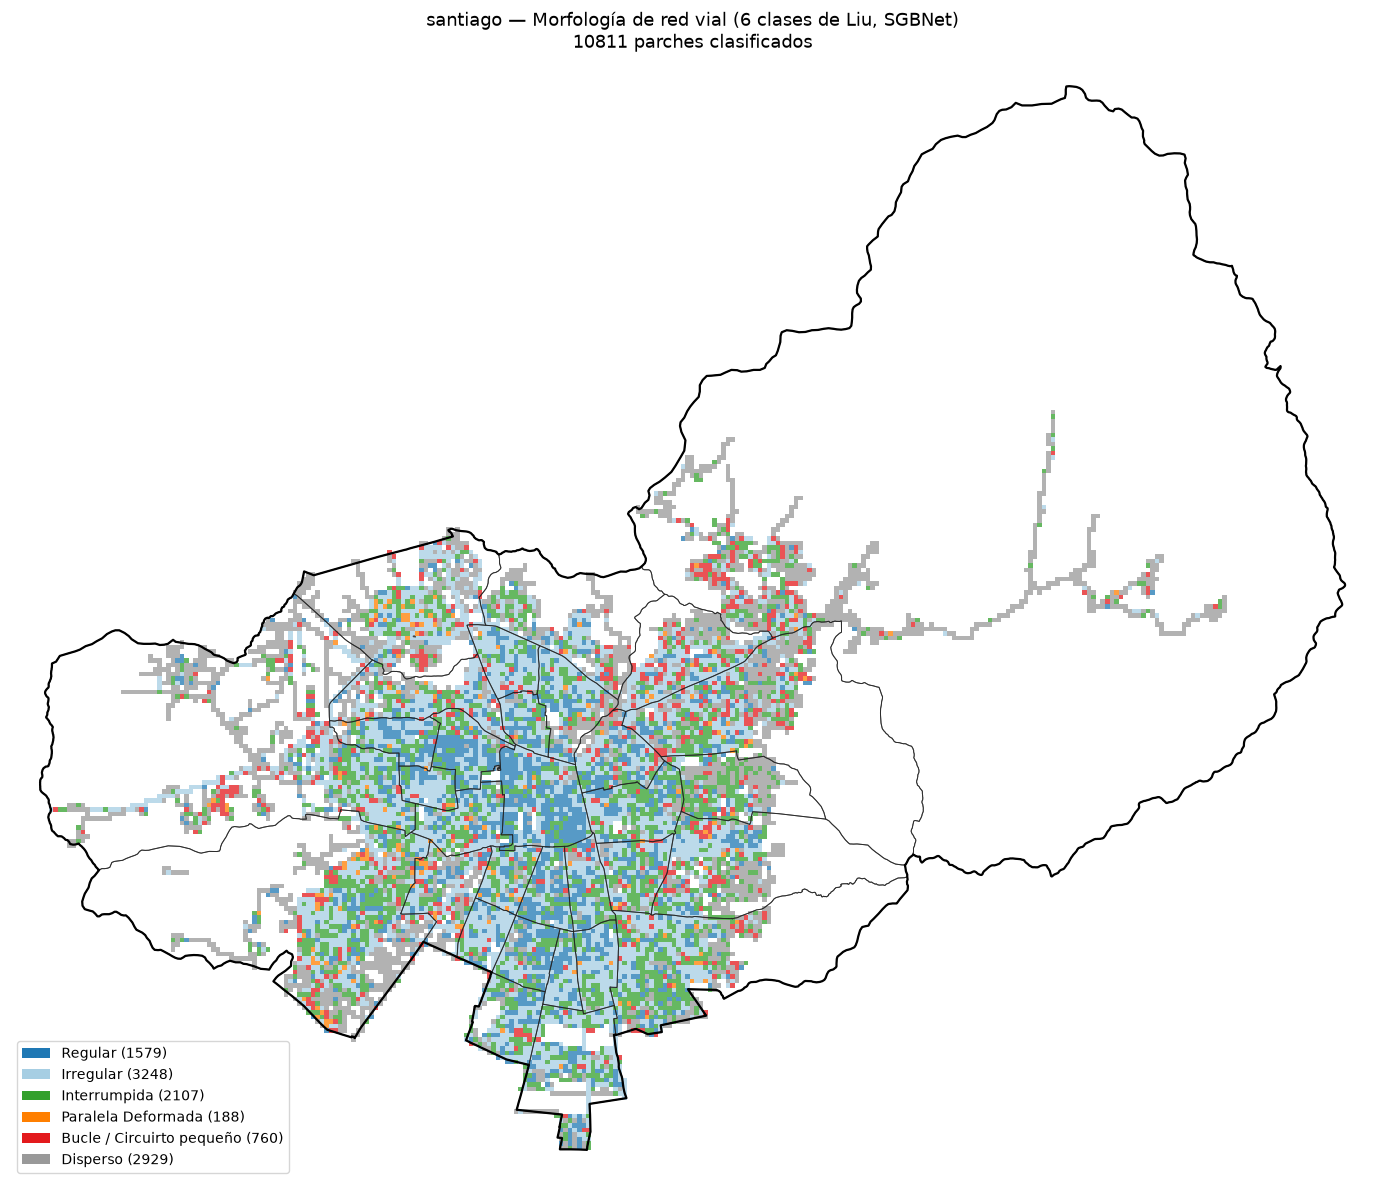

In [16]:
# ============================================================
# 7. Mapa estático de la provincia
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

gdf_3857 = gdf_parches.to_crs(3857)
comunas = gpd.read_file(DATOS / f"comunas_{NOMBRE_CIUDAD.lower()}.geojson").to_crs(3857)
# la consulta admin_level=8 trae relaciones de todo Chile: quedarse solo con
# las comunas cuyo punto representativo cae dentro de la provincia
comunas = comunas[comunas.representative_point().within(poligono_prov.buffer(500))]
print("Comunas dentro de la provincia:", len(comunas))

fig, ax = plt.subplots(figsize=(15, 12))
for cls, info in CLASES.items():
    sub = gdf_3857[gdf_3857["liu_class"] == info["nombre"]]
    if len(sub):
        sub.plot(ax=ax, color=info["color"], alpha=0.75, edgecolor="none")

comunas.boundary.plot(ax=ax, color="#222222", linewidth=0.7, alpha=0.8)
prov.boundary.plot(ax=ax, color="black", linewidth=1.6)

conteo = gdf_parches.groupby("liu_class").size()
ax.legend(handles=[Patch(facecolor=v["color"],
                          label=f'{v["nombre"]} ({conteo.get(v["nombre"], 0)})')
                   for v in CLASES.values()], loc="lower left", fontsize=10)

#ax.set_title("Provincia de Santiago — Morfología de red vial (6 clases de Liu, SGBNet)\n"
#             f"{len(gdf_parches)} parches de 1×1 km clasificados", fontsize=13)
ax.set_title(f"{NOMBRE_CIUDAD} — Morfología de red vial (6 clases de Liu, SGBNet)\n"
             f"{len(gdf_parches)} parches clasificados", fontsize=13)

pminx, pminy, pmaxx, pmaxy = poligono_prov.bounds
ax.set_xlim(pminx - 2000, pmaxx + 2000)
ax.set_ylim(pminy - 2000, pmaxy + 2000)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(DATOS_OUT / ARCHIVO_MAPA_OUT, dpi=150, bbox_inches="tight")
plt.show()
